
# CPU Segmentation Benchmark — COCO-Sampled (300 Images)

Compare four segmentation models on the **same frozen 300-image COCO benchmark**:

- YOLO11n-seg
- FastSAM-s
- MobileSAM
- SAM2.1-Tiny

All inference is forced to **CPU**.

### Evaluation protocol

- **MobileSAM / FastSAM / SAM2.1-Tiny:** the fixed COCO ground-truth bounding box is supplied as the prompt. This isolates mask quality from detection quality.
- **YOLO11n-seg:** normal detection + segmentation is performed. The predicted instance of the target COCO class with the highest box IoU against the target box is selected.
- Quality: IoU, Dice, precision, recall, success rate
- Efficiency: median latency, P95 latency, parameters, weight size
- Plots: quality vs time, quality vs model size, latency distribution, category heatmap, qualitative masks


In [29]:

!pip -q install -U ultralytics pycocotools psutil pandas matplotlib seaborn tqdm

import os
import time
import json
import gc
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import psutil

warnings.filterwarnings("ignore")

# HARD CPU-ONLY SETUP
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
torch.set_num_threads(4)

try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    print("⚠️ PyTorch inter-op threads already initialized; keeping existing setting.")

print("Torch:", torch.__version__)
print("Device: CPU")
print("Torch threads:", torch.get_num_threads())
print("Torch inter-op threads:", torch.get_num_interop_threads())

⚠️ PyTorch inter-op threads already initialized; keeping existing setting.
Torch: 2.10.0+cpu
Device: CPU
Torch threads: 4
Torch inter-op threads: 1


In [30]:

DATASET_ROOT = "/kaggle/input/datasets/mayankmishra2006/coco-sampled"

IMAGE_DIR = os.path.join(DATASET_ROOT, "images")
MASK_DIR = os.path.join(DATASET_ROOT, "masks")
CSV_PATH = os.path.join(DATASET_ROOT, "benchmark_300.csv")

df = pd.read_csv(CSV_PATH)

print("Images:", len(df))
print("Unique image IDs:", df.image_id.nunique())
print("\nCategory distribution:")
print(df.target_category.value_counts().sort_index())

assert len(df) == 300
assert df.image_id.nunique() == 300

print("\nBenchmark loaded successfully.")


Images: 300
Unique image IDs: 300

Category distribution:
target_category
bicycle       20
bird          20
bottle        20
bus           20
car           20
cat           20
cell phone    20
chair         20
couch         20
dog           20
horse         20
laptop        20
motorcycle    20
person        20
truck         20
Name: count, dtype: int64

Benchmark loaded successfully.


In [31]:

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use 20 or 50 while debugging.
# Use 300 for the final benchmark.
N_IMAGES = 300

bench = df.sort_values(
    ["target_category", "image_id"]
).reset_index(drop=True)

if N_IMAGES is not None:
    bench = bench.iloc[:N_IMAGES].copy()

print("Running:", len(bench), "images")


Running: 300 images


In [32]:
from ultralytics import YOLO, SAM, FastSAM

MODEL_CONFIG = {
    "YOLOv8n-seg": {"type": "yolo", "weights": "yolov8n-seg.pt"},
    "YOLO11n-seg": {"type": "yolo", "weights": "yolo11n-seg.pt"},
    "YOLO26n-seg": {"type": "yolo", "weights": "yolo26n-seg.pt"},
    "FastSAM-s": {"type": "fastsam", "weights": "FastSAM-s.pt"},
    "MobileSAM": {"type": "sam", "weights": "mobile_sam.pt"},
    "SAM2.1-Tiny": {"type": "sam", "weights": "sam2.1_t.pt"},
}

# All models use CPU PyTorch in the primary benchmark.
DEVICE = "cpu"

print("Models:")
for name, cfg in MODEL_CONFIG.items():
    print(f"  {name:16s} -> {cfg['weights']}")


Models:
  YOLOv8n-seg      -> yolov8n-seg.pt
  YOLO11n-seg      -> yolo11n-seg.pt
  YOLO26n-seg      -> yolo26n-seg.pt
  FastSAM-s        -> FastSAM-s.pt
  MobileSAM        -> mobile_sam.pt
  SAM2.1-Tiny      -> sam2.1_t.pt


In [33]:

def load_model(model_name):
    cfg = MODEL_CONFIG[model_name]

    if cfg["type"] == "yolo":
        return YOLO(cfg["weights"])
    if cfg["type"] == "fastsam":
        return FastSAM(cfg["weights"])
    if cfg["type"] == "sam":
        return SAM(cfg["weights"])

    raise ValueError(cfg["type"])


def count_parameters(model):
    try:
        return sum(p.numel() for p in model.model.parameters())
    except Exception:
        return np.nan


def find_weight_file(filename):
    roots = [
        Path.home() / ".cache" / "ultralytics",
        Path("/kaggle/working"),
        Path("/root/.cache"),
    ]

    matches = []
    for root in roots:
        if root.exists():
            matches.extend(root.rglob(filename))

    return str(matches[0]) if matches else None


def weight_size_mb(filename):
    path = find_weight_file(filename)
    if path is None:
        return np.nan
    return os.path.getsize(path) / (1024**2)


print("Helpers ready.")


Helpers ready.


In [34]:

COCO_NAMES = [
    "person","bicycle","car","motorcycle","airplane","bus","train","truck","boat",
    "traffic light","fire hydrant","stop sign","parking meter","bench","bird","cat",
    "dog","horse","sheep","cow","elephant","bear","zebra","giraffe","backpack",
    "umbrella","handbag","tie","suitcase","frisbee","skis","snowboard","sports ball",
    "kite","baseball bat","baseball glove","skateboard","surfboard","tennis racket",
    "bottle","wine glass","cup","fork","knife","spoon","bowl","banana","apple",
    "sandwich","orange","broccoli","carrot","hot dog","pizza","donut","cake","chair",
    "couch","potted plant","bed","dining table","toilet","tv","laptop","mouse",
    "remote","keyboard","cell phone","microwave","oven","toaster","sink",
    "refrigerator","book","clock","vase","scissors","teddy bear","hair drier",
    "toothbrush"
]

COCO_TO_YOLO = {
    name: i for i, name in enumerate(COCO_NAMES)
}

for category in bench.target_category.unique():
    assert category in COCO_TO_YOLO

print("COCO class mapping verified.")


COCO class mapping verified.


In [35]:

def read_image(path):
    return np.array(Image.open(path).convert("RGB"))


def load_gt_mask(row):
    mask_name = row["file_name"].replace(".jpg", ".png")
    mask_path = os.path.join(MASK_DIR, mask_name)
    return np.array(
        Image.open(mask_path).convert("L")
    ) > 127


def row_bbox_xyxy(row):
    return [
        float(row.bbox_x),
        float(row.bbox_y),
        float(row.bbox_x + row.bbox_w),
        float(row.bbox_y + row.bbox_h),
    ]


def mask_iou(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    inter = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    return inter / union if union else 1.0


def dice_score(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    inter = np.logical_and(pred, gt).sum()
    denom = pred.sum() + gt.sum()
    return 2 * inter / denom if denom else 1.0


def precision_recall(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return precision, recall


def bbox_iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0, ix2 - ix1)
    ih = max(0, iy2 - iy1)

    inter = iw * ih

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - inter

    return inter / union if union else 0.0


def current_rss_mb():
    return (
        psutil.Process(
            os.getpid()
        ).memory_info().rss
        / (1024**2)
    )


print("Metric helpers ready.")


Metric helpers ready.


In [36]:

def extract_first_mask(results, H, W):
    if results is None or len(results) == 0:
        return None

    result = results[0]

    if result.masks is None:
        return None

    masks = result.masks.data.cpu().numpy()

    if len(masks) == 0:
        return None

    mask = masks[0].astype(bool)

    if mask.shape != (H, W):
        mask_img = Image.fromarray(
            mask.astype(np.uint8) * 255
        )
        mask_img = mask_img.resize(
            (W, H),
            Image.Resampling.NEAREST
        )
        mask = np.array(mask_img) > 127

    return mask


def predict_prompted(model, model_type, image, bbox):
    H, W = image.shape[:2]

    if model_type == "sam":
        results = model.predict(
            source=image,
            bboxes=[bbox],
            device="cpu",
            verbose=False,
            retina_masks=True,
        )

    elif model_type == "fastsam":
        results = model.predict(
            source=image,
            bboxes=[bbox],
            device="cpu",
            verbose=False,
            retina_masks=True,
            imgsz=1024,
        )

    else:
        raise ValueError(model_type)

    return extract_first_mask(
        results, H, W
    )


def predict_yolo(model, image, target_class, gt_bbox):
    H, W = image.shape[:2]
    class_id = COCO_TO_YOLO[target_class]

    results = model.predict(
        source=image,
        device="cpu",
        verbose=False,
        retina_masks=True,
        classes=[class_id],
        conf=0.001,
        imgsz=640,
    )

    if not results:
        return None, None

    result = results[0]

    if result.boxes is None:
        return None, None

    if result.masks is None:
        return None, None

    boxes = result.boxes.xyxy.cpu().numpy()
    masks = result.masks.data.cpu().numpy().astype(bool)

    if len(boxes) == 0:
        return None, None

    scores = [
        bbox_iou_xyxy(box, gt_bbox)
        for box in boxes
    ]

    best_idx = int(np.argmax(scores))
    mask = masks[best_idx]

    if mask.shape != (H, W):
        mask_img = Image.fromarray(
            mask.astype(np.uint8) * 255
        )
        mask_img = mask_img.resize(
            (W, H),
            Image.Resampling.NEAREST
        )
        mask = np.array(mask_img) > 127

    confidence = float(
        result.boxes.conf[best_idx]
        .cpu()
        .item()
    )

    return mask, confidence


print("Inference adapters ready.")


Inference adapters ready.


In [37]:

def benchmark_model(model_name, model):
    cfg = MODEL_CONFIG[model_name]
    rows = []

    # Warm-up. Not included in reported latency.
    warm_row = bench.iloc[0]

    warm_img = read_image(
        os.path.join(
            IMAGE_DIR,
            warm_row.file_name
        )
    )

    warm_bbox = row_bbox_xyxy(warm_row)

    try:
        if cfg["type"] == "yolo":
            predict_yolo(
                model,
                warm_img,
                warm_row.target_category,
                warm_bbox
            )
        else:
            predict_prompted(
                model,
                cfg["type"],
                warm_img,
                warm_bbox
            )
    except Exception as e:
        print("Warm-up warning:", repr(e))

    gc.collect()

    for _, row in tqdm(
        bench.iterrows(),
        total=len(bench),
        desc=model_name
    ):
        image = read_image(
            os.path.join(
                IMAGE_DIR,
                row.file_name
            )
        )

        gt = load_gt_mask(row)
        bbox = row_bbox_xyxy(row)

        rss_before = current_rss_mb()
        start = time.perf_counter()

        try:
            if cfg["type"] == "yolo":
                pred, confidence = predict_yolo(
                    model,
                    image,
                    row.target_category,
                    bbox
                )
            else:
                pred = predict_prompted(
                    model,
                    cfg["type"],
                    image,
                    bbox
                )
                confidence = np.nan

            latency_ms = (
                time.perf_counter() - start
            ) * 1000

            rss_after = current_rss_mb()

            if pred is None:
                iou = 0.0
                dice = 0.0
                precision = 0.0
                recall = 0.0
                success = 0
            else:
                iou = mask_iou(pred, gt)
                dice = dice_score(pred, gt)
                precision, recall = (
                    precision_recall(pred, gt)
                )
                success = 1

            rows.append({
                "model": model_name,
                "image_id": row.image_id,
                "file_name": row.file_name,
                "category": row.target_category,
                "latency_ms": latency_ms,
                "iou": iou,
                "dice": dice,
                "precision": precision,
                "recall": recall,
                "confidence": confidence,
                "success": success,
                "rss_delta_mb": max(
                    0,
                    rss_after - rss_before
                ),
            })

        except Exception as e:
            rows.append({
                "model": model_name,
                "image_id": row.image_id,
                "file_name": row.file_name,
                "category": row.target_category,
                "latency_ms": np.nan,
                "iou": 0.0,
                "dice": 0.0,
                "precision": 0.0,
                "recall": 0.0,
                "confidence": np.nan,
                "success": 0,
                "rss_delta_mb": np.nan,
                "error": repr(e),
            })

    return pd.DataFrame(rows)


print("Benchmark runner ready.")


Benchmark runner ready.



## Run the benchmark

First use `N_IMAGES = 20` or `50` to verify that every model works.

Then change it to `300` for the final benchmark.

Models are loaded and deleted one at a time to control RAM.


In [38]:
all_results = []
model_summary = []
failed_models = []

for model_name, cfg in MODEL_CONFIG.items():

    print("\n" + "=" * 72)
    print("MODEL:", model_name)
    print("=" * 72)

    gc.collect()

    try:
        model = load_model(model_name)

        params = count_parameters(model)
        size_mb = weight_size_mb(cfg["weights"])

        print(f"Parameters: {params / 1e6:.2f} M")
        print(f"Weight size: {size_mb:.2f} MB")

        result_df = benchmark_model(
            model_name,
            model
        )

        all_results.append(result_df)

        model_summary.append({
            "model": model_name,
            "backend": "PyTorch CPU",
            "parameters": params,
            "parameters_M": (
                params / 1e6 if pd.notna(params) else np.nan
            ),
            "weight_size_MB": size_mb,
            "mean_latency_ms": result_df.latency_ms.mean(),
            "median_latency_ms": result_df.latency_ms.median(),
            "p95_latency_ms": result_df.latency_ms.quantile(0.95),
            "mean_IoU": result_df.iou.mean(),
            "mean_Dice": result_df.dice.mean(),
            "mean_precision": result_df.precision.mean(),
            "mean_recall": result_df.recall.mean(),
            "success_rate": result_df.success.mean(),
            "mean_rss_delta_MB": result_df.rss_delta_mb.mean(),
        })

        del model
        gc.collect()

    except Exception as e:
        print(f"SKIPPED {model_name}: {repr(e)}")
        failed_models.append({
            "model": model_name,
            "error": repr(e)
        })
        gc.collect()

results_df = (
    pd.concat(all_results, ignore_index=True)
    if all_results else pd.DataFrame()
)

summary_df = pd.DataFrame(model_summary)

if not summary_df.empty:
    summary_df["iou_per_second"] = (
        summary_df["mean_IoU"] /
        (summary_df["median_latency_ms"] / 1000)
    )
    summary_df["images_per_second"] = (
        1000 / summary_df["median_latency_ms"]
    )

print("\nCompleted models:")
display(summary_df)

if failed_models:
    print("\nModels that failed:")
    display(pd.DataFrame(failed_models))



MODEL: YOLOv8n-seg
Parameters: 3.41 M
Weight size: 6.74 MB


YOLOv8n-seg:   0%|          | 0/300 [00:00<?, ?it/s]


MODEL: YOLO11n-seg
Parameters: 2.88 M
Weight size: 5.90 MB


YOLO11n-seg:   0%|          | 0/300 [00:00<?, ?it/s]


MODEL: YOLO26n-seg
Parameters: 3.13 M
Weight size: 6.41 MB


...

MobileSAM:   0%|          | 0/300 [00:00<?, ?it/s]


MODEL: SAM2.1-Tiny
Parameters: 38.96 M
Weight size: 74.49 MB


SAM2.1-Tiny:   0%|          | 0/300 [00:00<?, ?it/s]


Completed models:


,model,backend,parameters,parameters_M,weight_size_MB,mean_latency_ms,median_latency_ms,p95_latency_ms,mean_IoU,mean_Dice,mean_precision,mean_recall,success_rate,mean_rss_delta_MB,iou_per_second,images_per_second
0,YOLOv8n-seg,PyTorch CPU,3409968,3.409968,6.744152,112.972384,98.837736,178.628612,0.653526,0.730366,0.708604,0.785741,0.956667,2.198867,6.612106,10.117593
1,YOLO11n-seg,PyTorch CPU,2876848,2.876848,5.896221,103.491913,91.980122,175.742100,0.642310,0.715747,0.697781,0.753839,0.916667,1.432930,6.983136,10.871914
2,YOLO26n-seg,PyTorch CPU,3126280,3.126280,6.408658,98.870347,89.345427,160.160783,0.668846,0.739860,0.723509,0.776417,0.926667,0.830807,7.486063,11.192515
3,FastSAM-s,PyTorch CPU,11790483,11.790483,22.746637,695.855811,672.056053,900.032057,0.605659,0.698620,0.704943,0.758789,1.000000,0.008216,0.901203,1.487971
4,MobileSAM,PyTorch CPU,10130092,10.130092,38.841463,1403.909946,1402.580563,1472.646311,0.792843,0.874005,0.871201,0.897091,1.000000,1.161029,0.565274,0.712972
5,SAM2.1-Tiny,PyTorch CPU,38962498,38.962498,74.487421,2633.432995,2631.126660,2699.884149,0.816603,0.889547,0.887114,0.909551,1.000000,0.744909,0.310363,0.380065


In [39]:

RESULT_DIR = (
    "/kaggle/working/"
    "segmentation_benchmark_results"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "per_image_results.csv"
    ),
    index=False
)

summary_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "model_summary.csv"
    ),
    index=False
)

with open(
    os.path.join(
        RESULT_DIR,
        "benchmark_config.json"
    ),
    "w"
) as f:
    json.dump(
        {
            "dataset_root": DATASET_ROOT,
            "n_images": len(bench),
            "seed": SEED,
            "cpu_only": True,
            "torch_threads": torch.get_num_threads(),
            "models": MODEL_CONFIG,
        },
        f,
        indent=2
    )

print(
    "Saved results to:",
    RESULT_DIR
)


Saved results to: /kaggle/working/segmentation_benchmark_results


## Main comparison plots

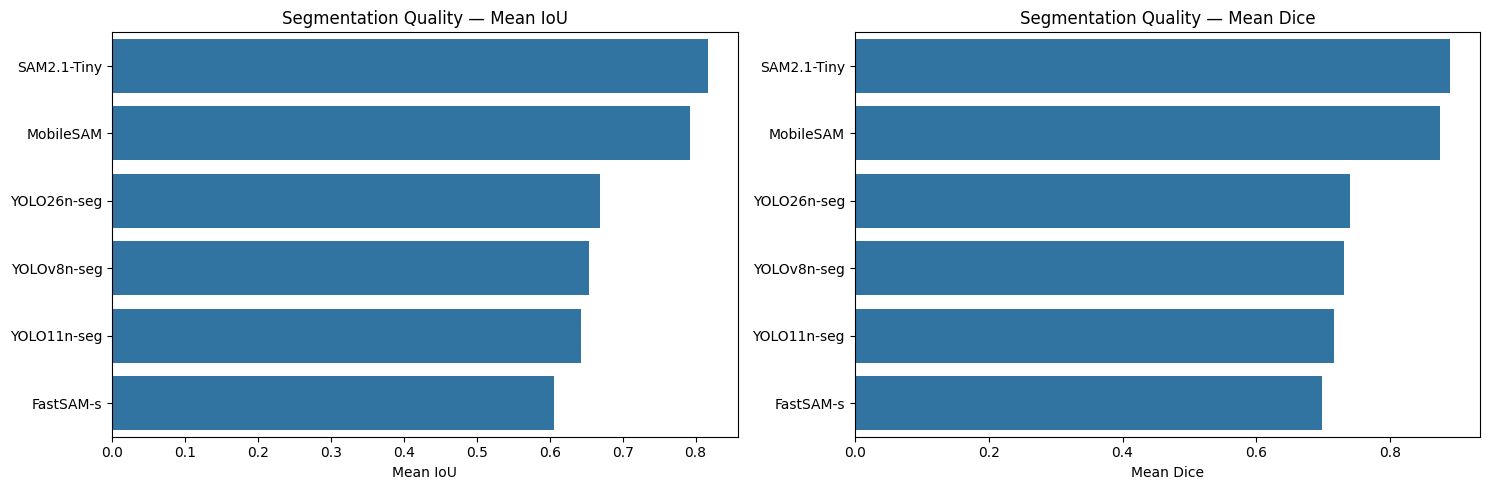

In [40]:

# IoU + Dice

plot_df = summary_df.sort_values(
    "mean_IoU",
    ascending=False
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

sns.barplot(
    data=plot_df,
    x="mean_IoU",
    y="model",
    ax=axes[0]
)

axes[0].set_title(
    "Segmentation Quality — Mean IoU"
)
axes[0].set_xlabel("Mean IoU")
axes[0].set_ylabel("")

sns.barplot(
    data=plot_df,
    x="mean_Dice",
    y="model",
    ax=axes[1]
)

axes[1].set_title(
    "Segmentation Quality — Mean Dice"
)
axes[1].set_xlabel("Mean Dice")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


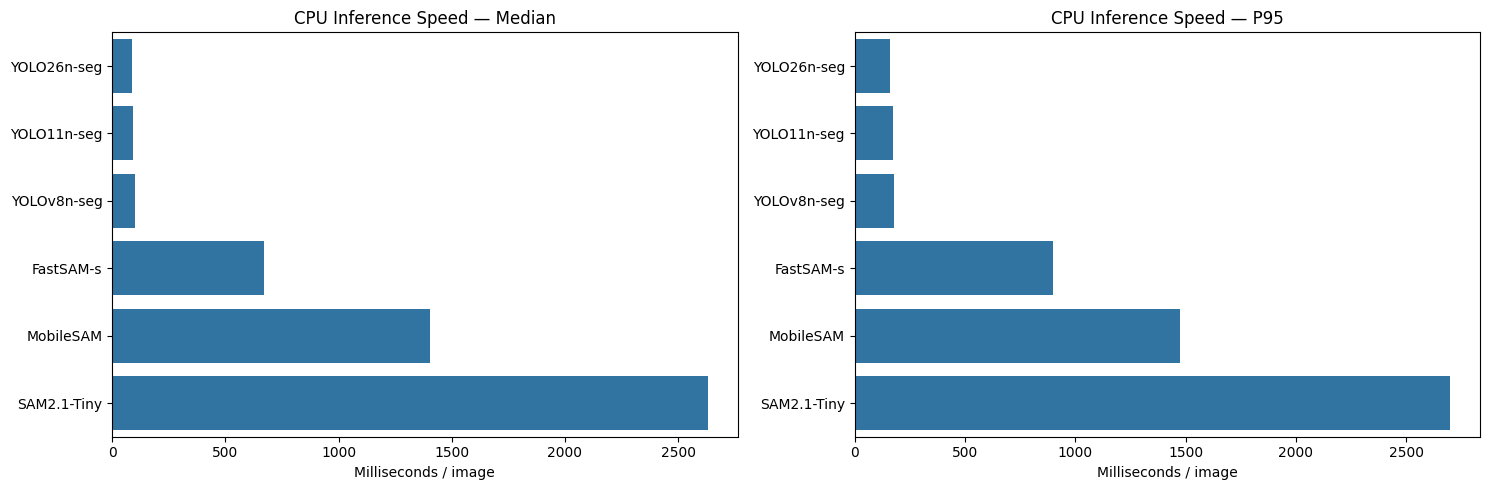

In [41]:

# CPU latency

plot_df = summary_df.sort_values(
    "median_latency_ms"
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

sns.barplot(
    data=plot_df,
    x="median_latency_ms",
    y="model",
    ax=axes[0]
)

axes[0].set_title(
    "CPU Inference Speed — Median"
)
axes[0].set_xlabel(
    "Milliseconds / image"
)
axes[0].set_ylabel("")

sns.barplot(
    data=plot_df,
    x="p95_latency_ms",
    y="model",
    ax=axes[1]
)

axes[1].set_title(
    "CPU Inference Speed — P95"
)
axes[1].set_xlabel(
    "Milliseconds / image"
)
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


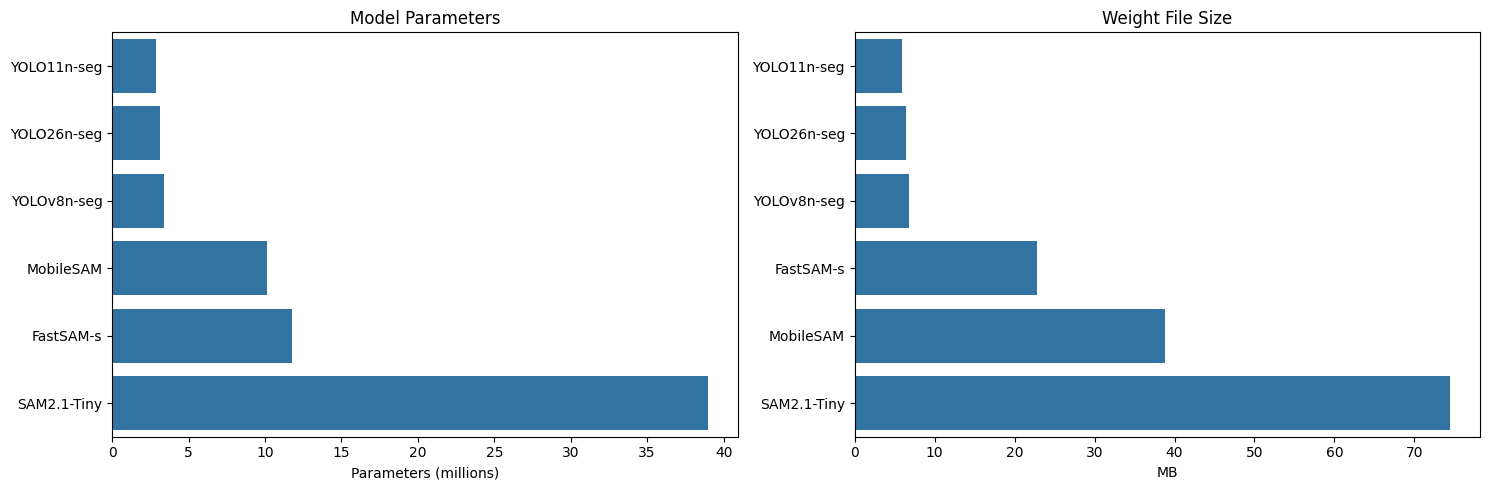

In [42]:

# Parameters + weight size

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

sns.barplot(
    data=summary_df.sort_values(
        "parameters_M"
    ),
    x="parameters_M",
    y="model",
    ax=axes[0]
)

axes[0].set_title(
    "Model Parameters"
)
axes[0].set_xlabel(
    "Parameters (millions)"
)
axes[0].set_ylabel("")

sns.barplot(
    data=summary_df.sort_values(
        "weight_size_MB"
    ),
    x="weight_size_MB",
    y="model",
    ax=axes[1]
)

axes[1].set_title(
    "Weight File Size"
)
axes[1].set_xlabel("MB")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


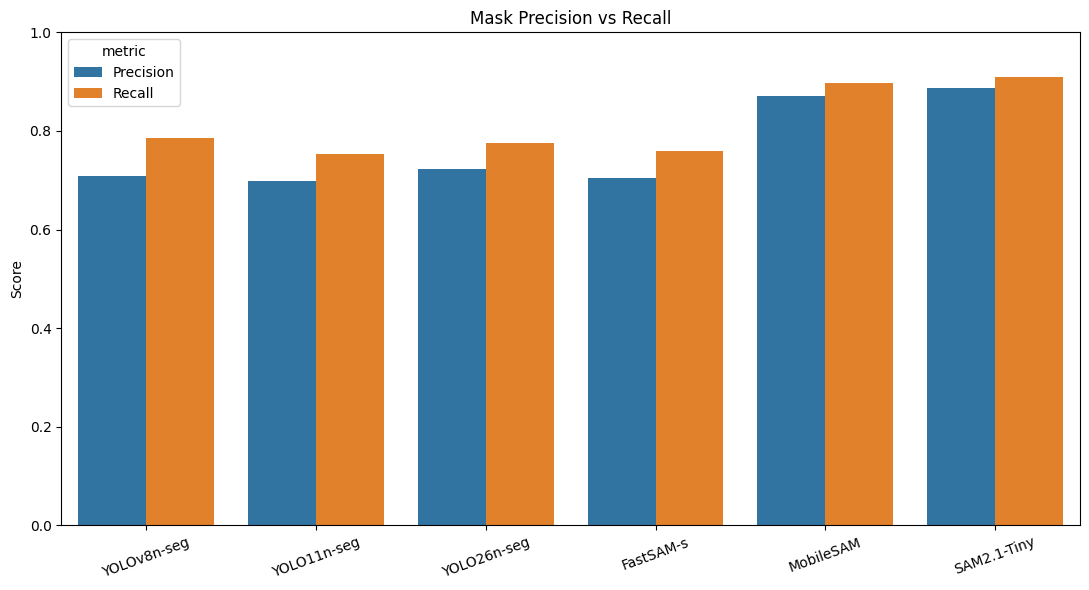

In [43]:

# Precision / Recall

long_pr = summary_df.melt(
    id_vars="model",
    value_vars=[
        "mean_precision",
        "mean_recall"
    ],
    var_name="metric",
    value_name="score"
)

long_pr["metric"] = long_pr[
    "metric"
].map({
    "mean_precision": "Precision",
    "mean_recall": "Recall"
})

plt.figure(figsize=(11, 6))

sns.barplot(
    data=long_pr,
    x="model",
    y="score",
    hue="metric"
)

plt.ylim(0, 1)
plt.title(
    "Mask Precision vs Recall"
)
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


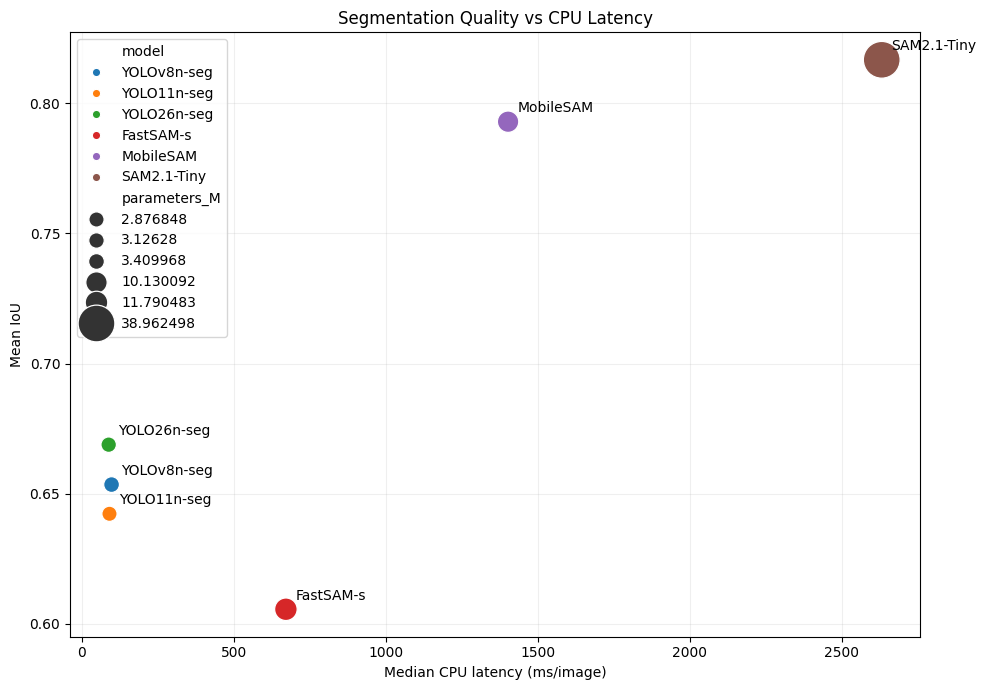

In [44]:

# ⭐ KEY PLOT:
# segmentation quality vs CPU latency

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=summary_df,
    x="median_latency_ms",
    y="mean_IoU",
    size="parameters_M",
    hue="model",
    sizes=(120, 700)
)

for _, r in summary_df.iterrows():
    plt.annotate(
        r["model"],
        (
            r["median_latency_ms"],
            r["mean_IoU"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.xlabel(
    "Median CPU latency (ms/image)"
)
plt.ylabel("Mean IoU")
plt.title(
    "Segmentation Quality vs CPU Latency"
)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


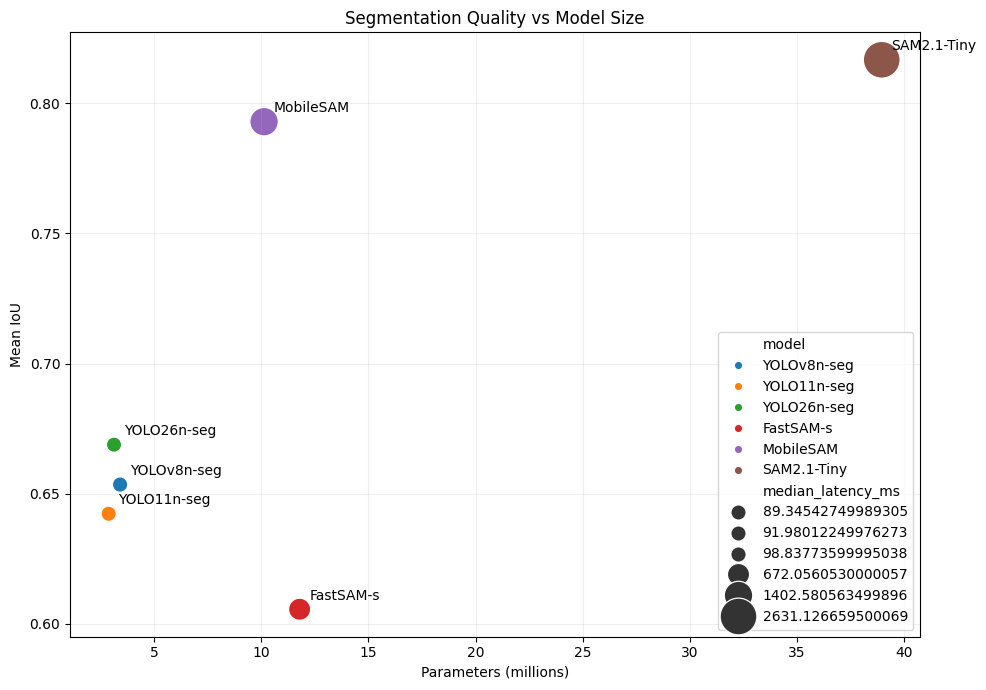

In [45]:

# ⭐ Quality vs model footprint

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=summary_df,
    x="parameters_M",
    y="mean_IoU",
    size="median_latency_ms",
    hue="model",
    sizes=(120, 700)
)

for _, r in summary_df.iterrows():
    plt.annotate(
        r["model"],
        (
            r["parameters_M"],
            r["mean_IoU"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.xlabel("Parameters (millions)")
plt.ylabel("Mean IoU")
plt.title(
    "Segmentation Quality vs Model Size"
)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [46]:

# Speedup relative to the slowest model

slowest = summary_df[
    "median_latency_ms"
].max()

summary_df["speedup_vs_slowest"] = (
    slowest /
    summary_df["median_latency_ms"]
)

display(
    summary_df[
        [
            "model",
            "mean_IoU",
            "mean_Dice",
            "median_latency_ms",
            "p95_latency_ms",
            "parameters_M",
            "weight_size_MB",
            "speedup_vs_slowest",
        ]
    ].sort_values(
        "median_latency_ms"
    )
)


,model,mean_IoU,mean_Dice,median_latency_ms,p95_latency_ms,parameters_M,weight_size_MB,speedup_vs_slowest
2,YOLO26n-seg,0.668846,0.739860,89.345427,160.160783,3.126280,6.408658,29.448923
1,YOLO11n-seg,0.642310,0.715747,91.980122,175.742100,2.876848,5.896221,28.605383
0,YOLOv8n-seg,0.653526,0.730366,98.837736,178.628612,3.409968,6.744152,26.620669
3,FastSAM-s,0.605659,0.698620,672.056053,900.032057,11.790483,22.746637,3.915040
4,MobileSAM,0.792843,0.874005,1402.580563,1472.646311,10.130092,38.841463,1.875918
5,SAM2.1-Tiny,0.816603,0.889547,2631.126660,2699.884149,38.962498,74.487421,1.000000


## Per-category analysis

In [47]:

category_results = (
    results_df
    .groupby(
        ["model", "category"]
    )
    .agg(
        mean_IoU=("iou", "mean"),
        mean_Dice=("dice", "mean"),
        median_latency_ms=(
            "latency_ms",
            "median"
        ),
        success_rate=("success", "mean"),
        n=("image_id", "count"),
    )
    .reset_index()
)

display(
    category_results.head(20)
)


,model,category,mean_IoU,mean_Dice,median_latency_ms,success_rate,n
0,FastSAM-s,bicycle,0.408118,0.502137,802.347349,1.0,20
1,FastSAM-s,bird,0.639525,0.726689,640.140361,1.0,20
2,FastSAM-s,bottle,0.662701,0.756818,684.287751,1.0,20
3,FastSAM-s,bus,0.711908,0.803214,770.150030,1.0,20
4,FastSAM-s,car,0.677172,0.749342,702.927484,1.0,20
5,FastSAM-s,cat,0.645862,0.758526,623.642733,1.0,20
6,FastSAM-s,cell phone,0.547398,0.607806,680.110111,1.0,20
7,FastSAM-s,chair,0.676374,0.755941,686.266495,1.0,20
8,FastSAM-s,couch,0.540735,0.656771,624.197864,1.0,20
9,FastSAM-s,dog,0.632325,0.729209,622.737823,1.0,20


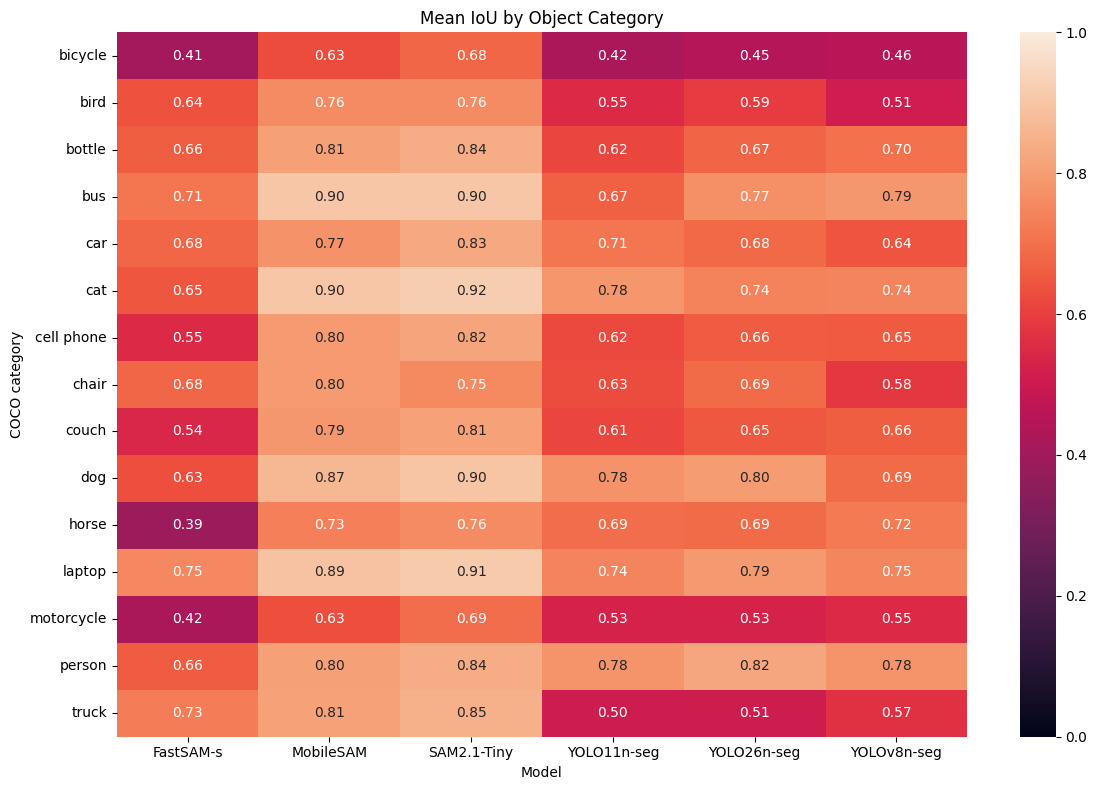

In [48]:

# IoU heatmap by category

heat = category_results.pivot(
    index="category",
    columns="model",
    values="mean_IoU"
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    heat,
    annot=True,
    fmt=".2f",
    vmin=0,
    vmax=1
)

plt.title(
    "Mean IoU by Object Category"
)
plt.xlabel("Model")
plt.ylabel("COCO category")
plt.tight_layout()
plt.show()


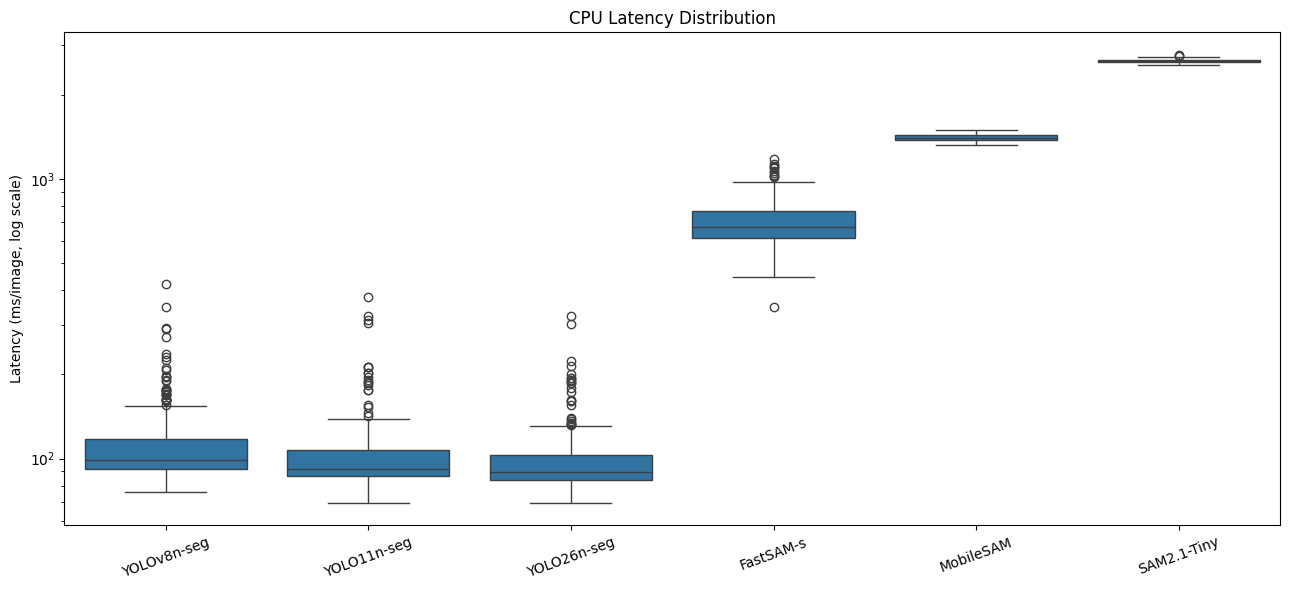

In [49]:

# Latency distribution

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=results_df,
    x="model",
    y="latency_ms"
)

plt.yscale("log")
plt.ylabel(
    "Latency (ms/image, log scale)"
)
plt.xlabel("")
plt.title(
    "CPU Latency Distribution"
)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Qualitative comparison

In [50]:

QUAL_N = min(8, len(bench))

qual = bench.sample(
    QUAL_N,
    random_state=42
)

prediction_store = {}

for model_name in MODEL_CONFIG:

    model = load_model(model_name)
    preds = {}

    for _, row in qual.iterrows():

        image = read_image(
            os.path.join(
                IMAGE_DIR,
                row.file_name
            )
        )

        bbox = row_bbox_xyxy(row)

        if MODEL_CONFIG[
            model_name
        ]["type"] == "yolo":

            pred, _ = predict_yolo(
                model,
                image,
                row.target_category,
                bbox
            )

        else:

            pred = predict_prompted(
                model,
                MODEL_CONFIG[
                    model_name
                ]["type"],
                image,
                bbox
            )

        preds[row.image_id] = pred

    prediction_store[
        model_name
    ] = preds

    del model
    gc.collect()

print(
    "Qualitative predictions ready."
)


Qualitative predictions ready.


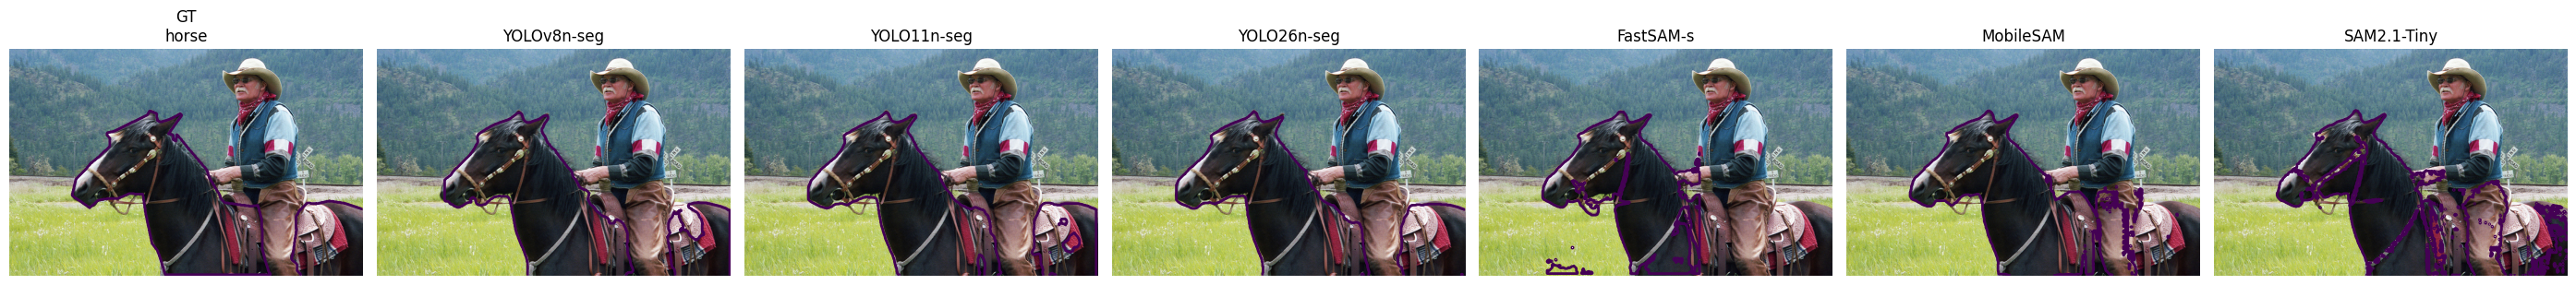

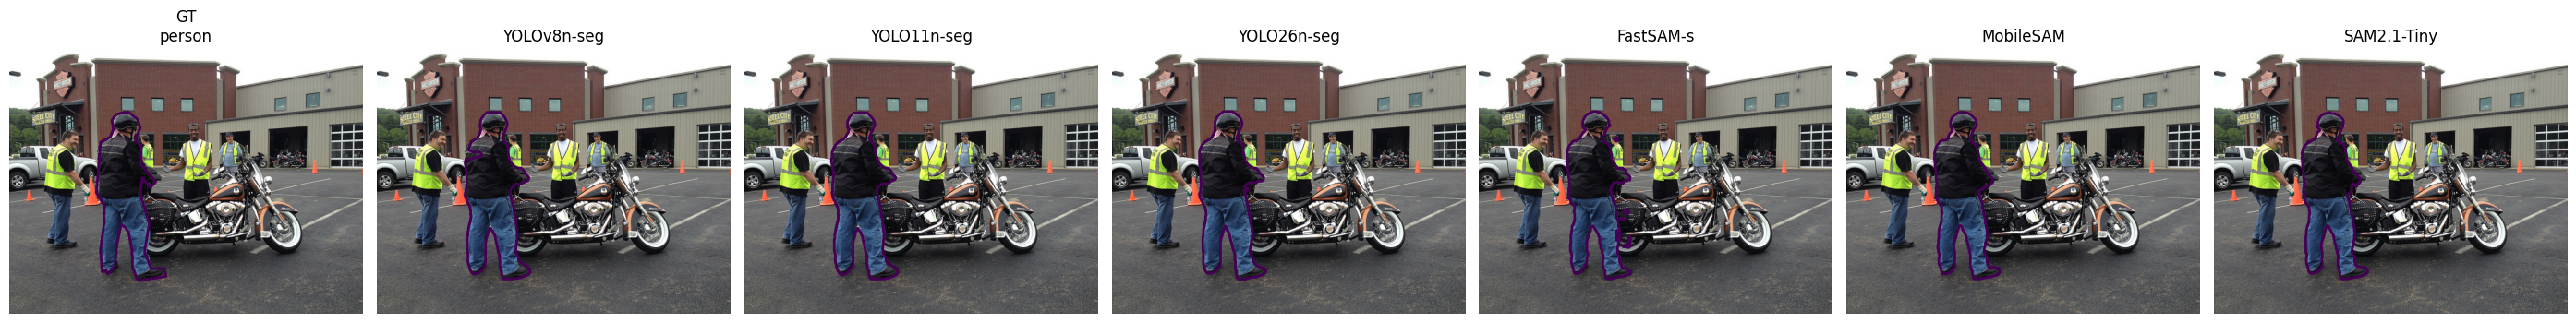

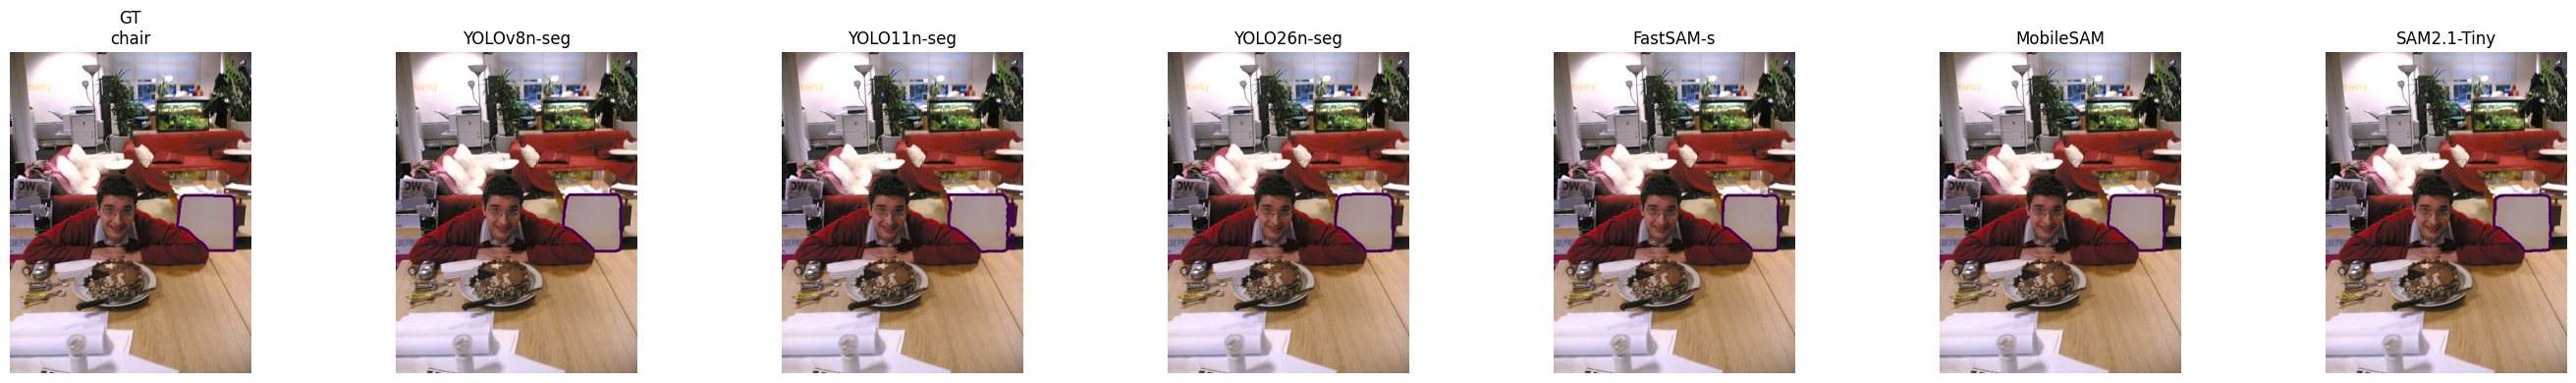

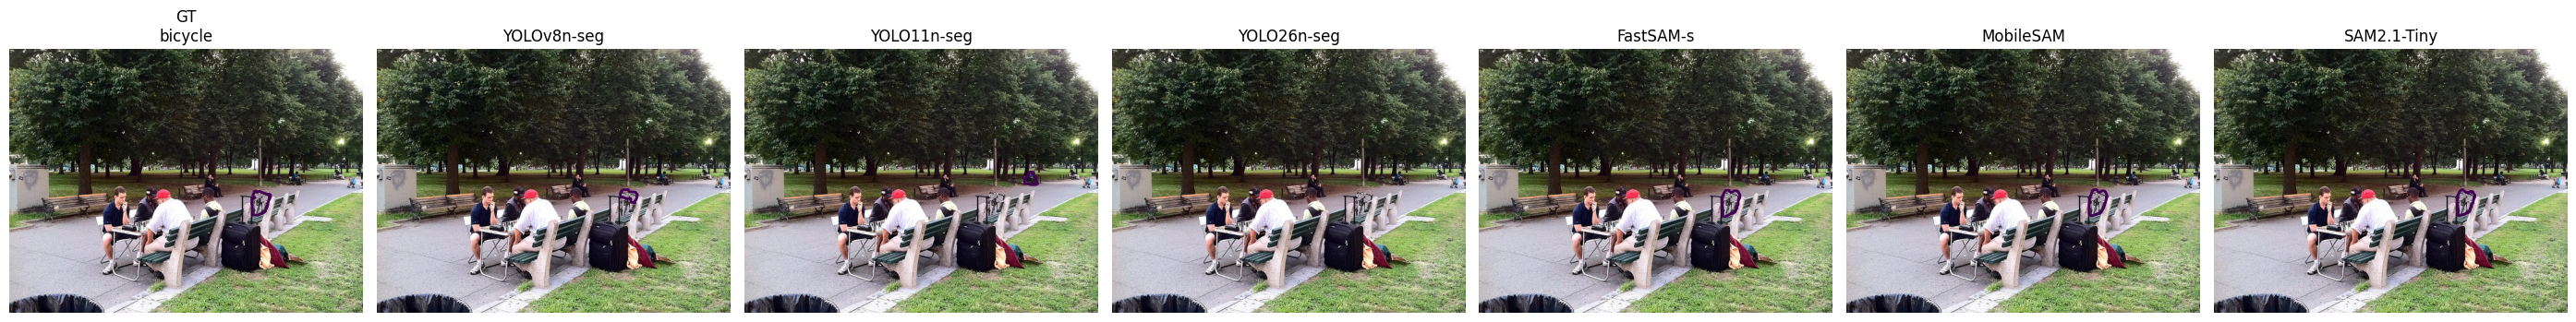

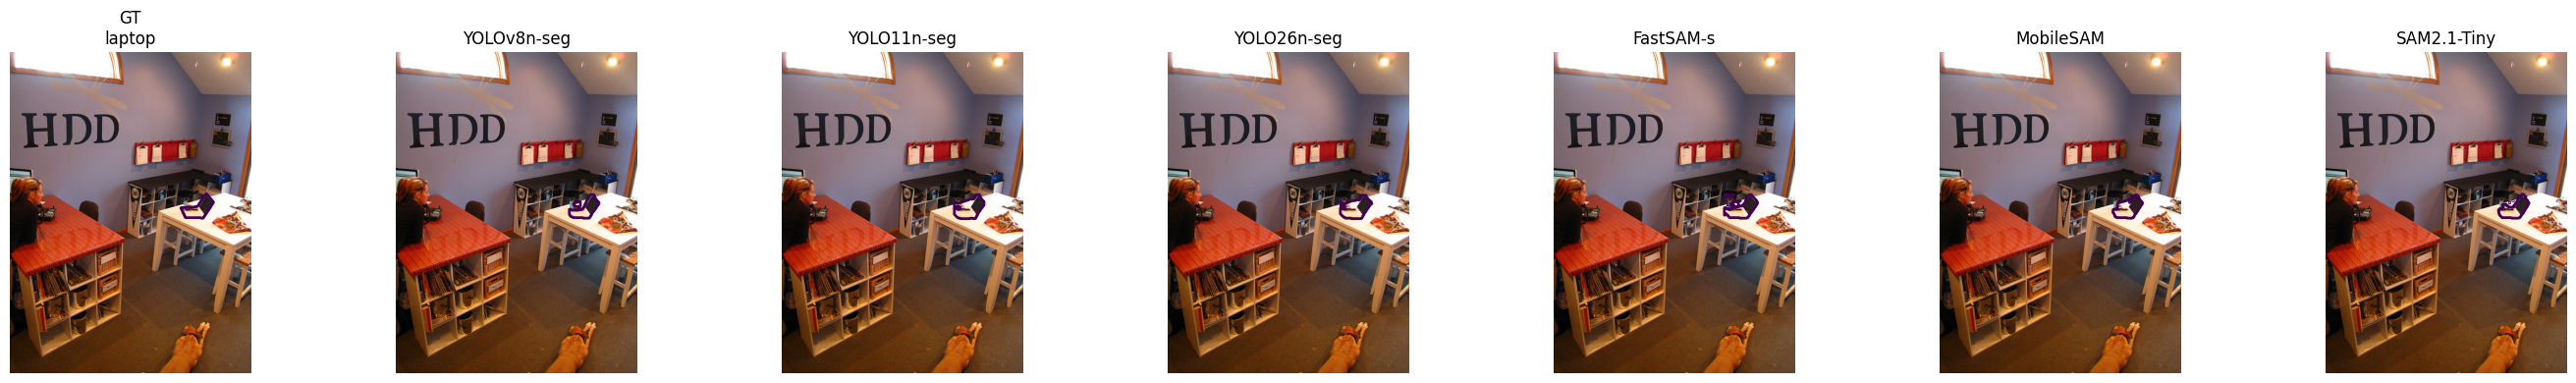

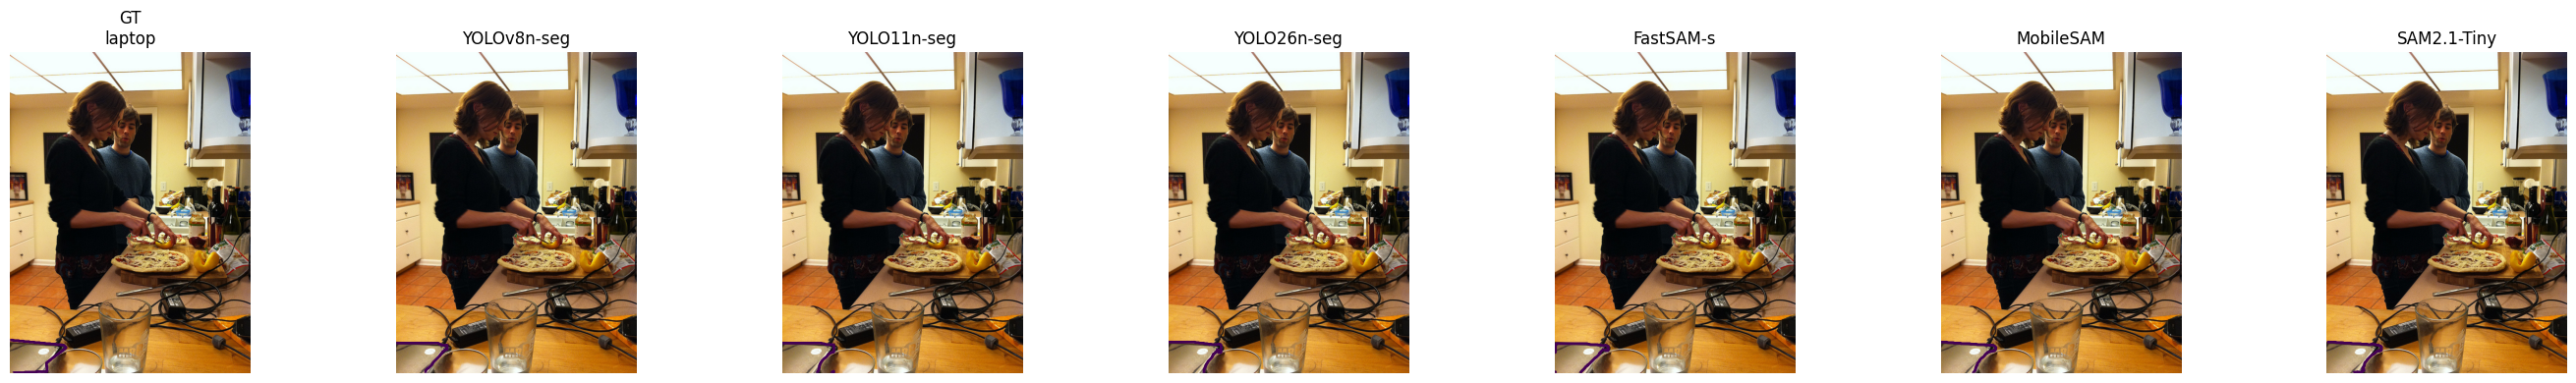

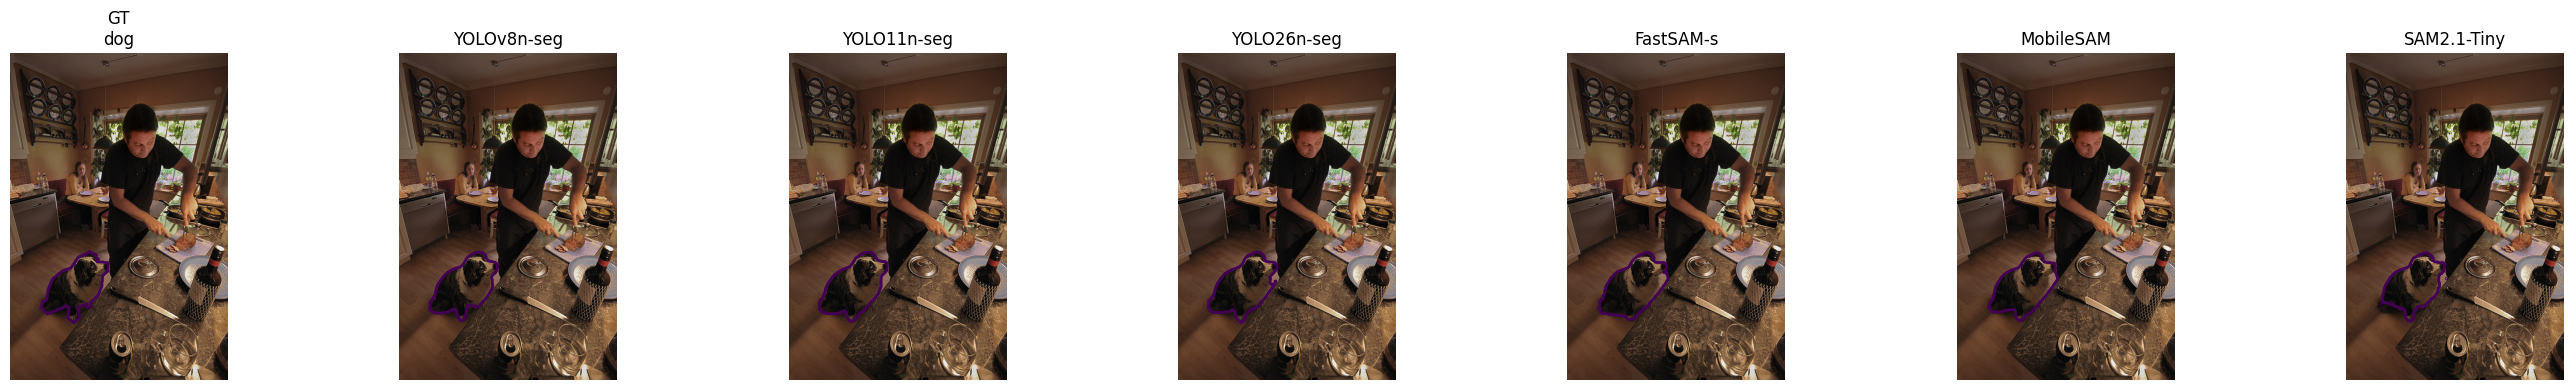

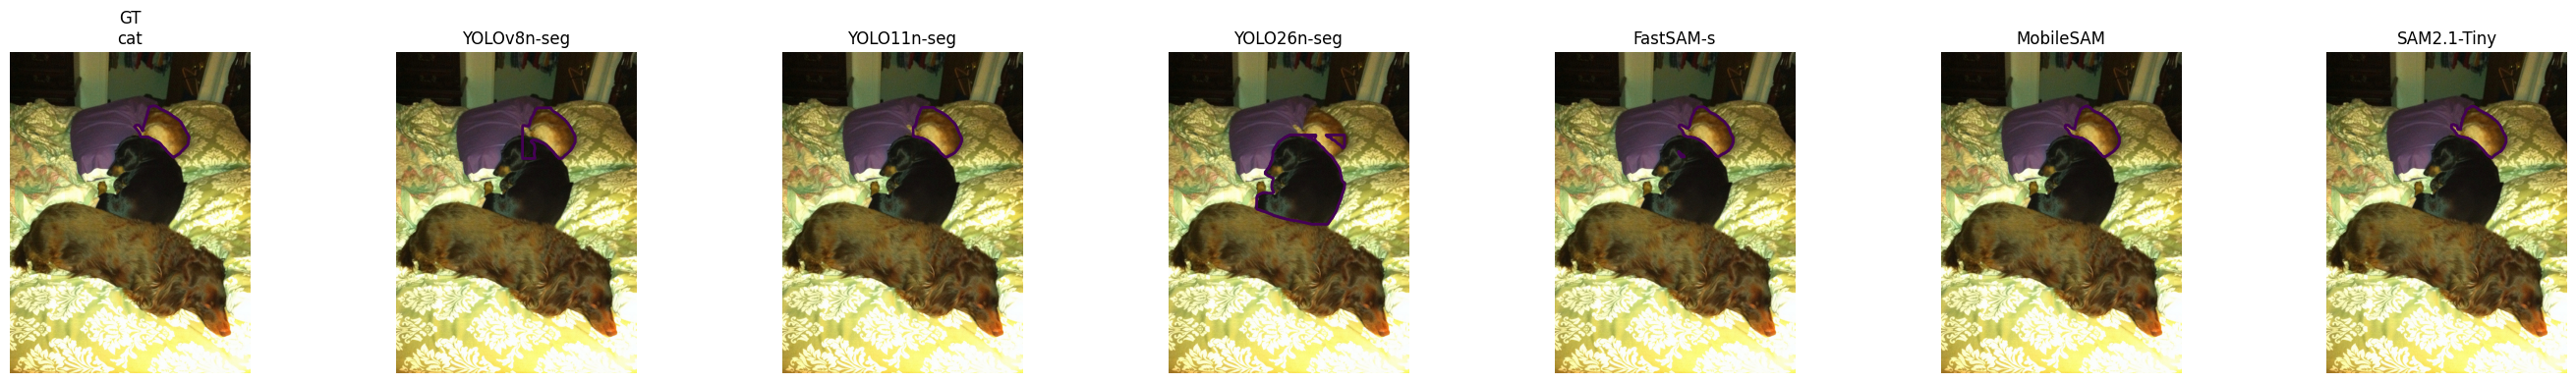

In [51]:

for _, row in qual.iterrows():

    image = read_image(
        os.path.join(
            IMAGE_DIR,
            row.file_name
        )
    )

    gt = load_gt_mask(row)

    n_models = len(MODEL_CONFIG)

    fig, axes = plt.subplots(
        1,
        n_models + 1,
        figsize=(4 * (n_models + 1), 4)
    )

    axes[0].imshow(image)

    axes[0].contour(
        gt,
        levels=[0.5],
        linewidths=2
    )

    axes[0].set_title(
        f"GT\n{row.target_category}"
    )

    axes[0].axis("off")

    for ax, model_name in zip(
        axes[1:],
        MODEL_CONFIG
    ):

        ax.imshow(image)

        pred = prediction_store[
            model_name
        ].get(row.image_id)

        if pred is not None:
            ax.contour(
                pred,
                levels=[0.5],
                linewidths=2
            )

        ax.set_title(model_name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


## Final report table

In [52]:

final_columns = [
    "model",
    "parameters_M",
    "weight_size_MB",
    "mean_IoU",
    "mean_Dice",
    "mean_precision",
    "mean_recall",
    "median_latency_ms",
    "p95_latency_ms",
    "success_rate",
]

final_table = (
    summary_df[
        final_columns
    ]
    .sort_values(
        "median_latency_ms"
    )
    .reset_index(drop=True)
)

display(
    final_table.style.format({
        "parameters_M": "{:.2f}",
        "weight_size_MB": "{:.2f}",
        "mean_IoU": "{:.4f}",
        "mean_Dice": "{:.4f}",
        "mean_precision": "{:.4f}",
        "mean_recall": "{:.4f}",
        "median_latency_ms": "{:.2f}",
        "p95_latency_ms": "{:.2f}",
        "success_rate": "{:.2%}",
    })
)

final_table.to_csv(
    os.path.join(
        RESULT_DIR,
        "FINAL_MODEL_COMPARISON.csv"
    ),
    index=False
)

category_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "CATEGORY_RESULTS.csv"
    ),
    index=False
)

print(
    "\nResults saved in:",
    RESULT_DIR
)


,model,parameters_M,weight_size_MB,mean_IoU,mean_Dice,mean_precision,mean_recall,median_latency_ms,p95_latency_ms,success_rate
0,YOLO26n-seg,3.13,6.41,0.6688,0.7399,0.7235,0.7764,89.35,160.16,92.67%
1,YOLO11n-seg,2.88,5.90,0.6423,0.7157,0.6978,0.7538,91.98,175.74,91.67%
2,YOLOv8n-seg,3.41,6.74,0.6535,0.7304,0.7086,0.7857,98.84,178.63,95.67%
3,FastSAM-s,11.79,22.75,0.6057,0.6986,0.7049,0.7588,672.06,900.03,100.00%
4,MobileSAM,10.13,38.84,0.7928,0.8740,0.8712,0.8971,1402.58,1472.65,100.00%
5,SAM2.1-Tiny,38.96,74.49,0.8166,0.8895,0.8871,0.9096,2631.13,2699.88,100.00%



Results saved in: /kaggle/working/segmentation_benchmark_results


AttributeError: 'Text' object has no attribute 'get_fontfeatures'

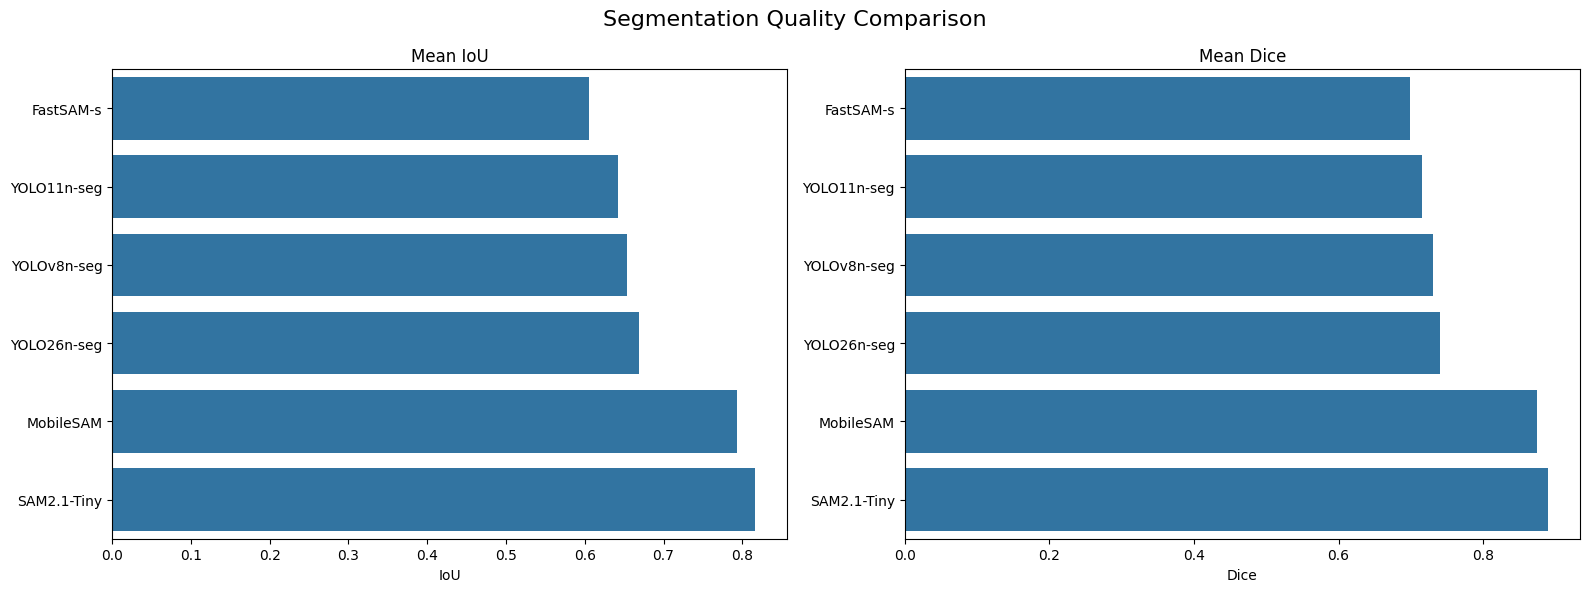

In [53]:

# ============================================================
# SAVE EVERYTHING: RAW DATA + ALL GRAPH DATA + ALL FIGURES
# ============================================================

from pathlib import Path
import shutil
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RESULT_ROOT = Path("/kaggle/working/segmentation_benchmark_results")
DATA_DIR = RESULT_ROOT / "data"
GRAPH_DIR = RESULT_ROOT / "graphs"
QUAL_DIR = GRAPH_DIR / "qualitative"
REPORT_DIR = RESULT_ROOT / "report"

for d in [DATA_DIR, GRAPH_DIR, QUAL_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)


# ---------- Raw experimental data ----------

results_df.to_csv(
    DATA_DIR / "per_image_results.csv",
    index=False
)

summary_df.to_csv(
    DATA_DIR / "model_summary.csv",
    index=False
)

category_results.to_csv(
    DATA_DIR / "category_results.csv",
    index=False
)

bench.to_csv(
    DATA_DIR / "benchmark_used.csv",
    index=False
)


# ---------- Experiment configuration ----------

config = {
    "dataset_root": DATASET_ROOT,
    "n_images": len(bench),
    "seed": SEED,
    "device": "cpu",
    "torch_threads": torch.get_num_threads(),
    "backend": "PyTorch CPU",
    "models": MODEL_CONFIG,
    "protocol": {
        "sam_fastsam": "fixed COCO GT bounding box used as prompt",
        "yolo": "target class filtered; prediction with highest bbox IoU against target box selected"
    }
}

with open(DATA_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)


# ---------- Plot data ----------

summary_df[
    [c for c in [
        "model", "parameters_M", "weight_size_MB",
        "mean_IoU", "mean_Dice",
        "median_latency_ms", "p95_latency_ms",
        "iou_per_second", "images_per_second"
    ] if c in summary_df.columns]
].to_csv(
    DATA_DIR / "plot_quality_speed_footprint.csv",
    index=False
)

category_results.to_csv(
    DATA_DIR / "plot_category_results.csv",
    index=False
)

results_df[
    [c for c in [
        "model", "image_id", "category",
        "latency_ms", "iou", "dice",
        "precision", "recall"
    ] if c in results_df.columns]
].to_csv(
    DATA_DIR / "plot_per_image_points.csv",
    index=False
)


# ---------- Helper ----------

def save_figure(fig, name):
    for ext in ["png", "svg", "pdf"]:
        fig.savefig(
            GRAPH_DIR / f"{name}.{ext}",
            dpi=300,
            bbox_inches="tight"
        )
    plt.close(fig)


valid = summary_df.dropna(
    subset=["mean_IoU", "median_latency_ms"]
).copy()


# ---------- 01: IoU + Dice ----------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=valid.sort_values("mean_IoU"),
    x="mean_IoU", y="model", ax=axes[0]
)
axes[0].set_title("Mean IoU")
axes[0].set_xlabel("IoU")
axes[0].set_ylabel("")

sns.barplot(
    data=valid.sort_values("mean_Dice"),
    x="mean_Dice", y="model", ax=axes[1]
)
axes[1].set_title("Mean Dice")
axes[1].set_xlabel("Dice")
axes[1].set_ylabel("")

fig.suptitle("Segmentation Quality Comparison", fontsize=16)
plt.tight_layout()
save_figure(fig, "01_quality_iou_dice")


# ---------- 02: CPU latency ----------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

lat = valid.melt(
    id_vars="model",
    value_vars=[
        "mean_latency_ms",
        "median_latency_ms",
        "p95_latency_ms"
    ],
    var_name="metric",
    value_name="latency_ms"
)

lat["metric"] = lat["metric"].map({
    "mean_latency_ms": "Mean",
    "median_latency_ms": "Median",
    "p95_latency_ms": "P95"
})

sns.barplot(
    data=lat, x="model", y="latency_ms",
    hue="metric", ax=axes[0]
)
axes[0].set_yscale("log")
axes[0].set_title("CPU Latency")
axes[0].set_ylabel("ms / image")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(
    data=results_df,
    x="model", y="latency_ms",
    ax=axes[1]
)
axes[1].set_yscale("log")
axes[1].set_title("Per-Image Latency Distribution")
axes[1].set_ylabel("ms / image")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
save_figure(fig, "02_cpu_latency")


# ---------- 03: model footprint ----------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=valid.sort_values("parameters_M"),
    x="parameters_M", y="model", ax=axes[0]
)
axes[0].set_title("Parameters")
axes[0].set_xlabel("Million parameters")
axes[0].set_ylabel("")

sns.barplot(
    data=valid.sort_values("weight_size_MB"),
    x="weight_size_MB", y="model", ax=axes[1]
)
axes[1].set_title("Weight File Size")
axes[1].set_xlabel("MB")
axes[1].set_ylabel("")

plt.tight_layout()
save_figure(fig, "03_model_footprint")


# ---------- 04: precision / recall ----------

pr = valid.melt(
    id_vars="model",
    value_vars=["mean_precision", "mean_recall"],
    var_name="metric",
    value_name="score"
)

pr["metric"] = pr["metric"].map({
    "mean_precision": "Precision",
    "mean_recall": "Recall"
})

fig, ax = plt.subplots(figsize=(13, 6))

sns.barplot(
    data=pr,
    x="model",
    y="score",
    hue="metric",
    ax=ax
)

ax.set_ylim(0, 1)
ax.set_title("Mask Precision vs Recall")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
save_figure(fig, "04_precision_recall")


# ---------- 05: quality vs CPU time ----------

fig, ax = plt.subplots(figsize=(11, 8))

sns.scatterplot(
    data=valid,
    x="median_latency_ms",
    y="mean_IoU",
    size="parameters_M",
    hue="model",
    sizes=(150, 850),
    ax=ax
)

for _, r in valid.iterrows():
    ax.annotate(
        r["model"],
        (r["median_latency_ms"], r["mean_IoU"]),
        xytext=(8, 8),
        textcoords="offset points"
    )

ax.set_title("Segmentation Quality vs CPU Inference Time")
ax.set_xlabel("Median CPU latency (ms/image)")
ax.set_ylabel("Mean IoU")
ax.grid(alpha=0.2)

plt.tight_layout()
save_figure(fig, "05_quality_vs_cpu_latency")


# ---------- 06: quality vs parameters ----------

fig, ax = plt.subplots(figsize=(11, 8))

sns.scatterplot(
    data=valid,
    x="parameters_M",
    y="mean_IoU",
    size="median_latency_ms",
    hue="model",
    sizes=(150, 850),
    ax=ax
)

for _, r in valid.iterrows():
    ax.annotate(
        r["model"],
        (r["parameters_M"], r["mean_IoU"]),
        xytext=(8, 8),
        textcoords="offset points"
    )

ax.set_title("Segmentation Quality vs Model Size")
ax.set_xlabel("Parameters (Millions)")
ax.set_ylabel("Mean IoU")
ax.grid(alpha=0.2)

plt.tight_layout()
save_figure(fig, "06_quality_vs_parameters")


# ---------- 07: success rate ----------

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=valid.sort_values("success_rate"),
    x="success_rate",
    y="model",
    ax=ax
)

ax.set_xlim(0, 1)
ax.set_title("Segmentation Success Rate")
ax.set_xlabel("Success rate")
ax.set_ylabel("")

plt.tight_layout()
save_figure(fig, "07_success_rate")


# ---------- 08: efficiency ----------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=valid.sort_values("iou_per_second"),
    x="iou_per_second",
    y="model",
    ax=axes[0]
)
axes[0].set_title("IoU per Second")
axes[0].set_xlabel("IoU / second")
axes[0].set_ylabel("")

sns.barplot(
    data=valid.sort_values("images_per_second"),
    x="images_per_second",
    y="model",
    ax=axes[1]
)
axes[1].set_title("CPU Throughput")
axes[1].set_xlabel("Images / second")
axes[1].set_ylabel("")

plt.tight_layout()
save_figure(fig, "08_efficiency")


# ---------- 09: category IoU heatmap ----------

if not category_results.empty:

    heat = category_results.pivot(
        index="category",
        columns="model",
        values="mean_IoU"
    )

    fig, ax = plt.subplots(figsize=(14, 9))

    sns.heatmap(
        heat,
        annot=True,
        fmt=".2f",
        vmin=0,
        vmax=1,
        ax=ax
    )

    ax.set_title("Mean IoU by COCO Category")
    ax.set_xlabel("Model")
    ax.set_ylabel("Category")

    plt.tight_layout()
    save_figure(fig, "09_category_iou_heatmap")


# ---------- 10: category latency heatmap ----------

if not category_results.empty:

    heat = category_results.pivot(
        index="category",
        columns="model",
        values="median_latency_ms"
    )

    fig, ax = plt.subplots(figsize=(14, 9))

    sns.heatmap(
        heat,
        annot=True,
        fmt=".0f",
        ax=ax
    )

    ax.set_title("Median CPU Latency by COCO Category")
    ax.set_xlabel("Model")
    ax.set_ylabel("Category")

    plt.tight_layout()
    save_figure(fig, "10_category_latency_heatmap")


# ---------- 11: IoU distribution ----------

fig, ax = plt.subplots(figsize=(14, 7))

sns.boxplot(
    data=results_df,
    x="model",
    y="iou",
    ax=ax
)

ax.set_ylim(0, 1)
ax.set_title("Per-Image IoU Distribution")
ax.set_xlabel("")
ax.set_ylabel("IoU")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
save_figure(fig, "11_iou_distribution")


# ---------- Excel report ----------

excel_path = REPORT_DIR / "segmentation_benchmark.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results_df.to_excel(
        writer, sheet_name="Per Image", index=False
    )
    summary_df.to_excel(
        writer, sheet_name="Model Summary", index=False
    )
    category_results.to_excel(
        writer, sheet_name="Category Results", index=False
    )
    bench.to_excel(
        writer, sheet_name="Benchmark", index=False
    )


# ---------- File manifest ----------

manifest = []

for p in RESULT_ROOT.rglob("*"):
    if p.is_file():
        manifest.append({
            "file": str(p.relative_to(RESULT_ROOT)),
            "size_MB": round(
                p.stat().st_size / (1024 ** 2),
                3
            )
        })

pd.DataFrame(manifest).to_csv(
    RESULT_ROOT / "FILE_MANIFEST.csv",
    index=False
)

print("Saved all tabular data and graphs.")
print("Results:", RESULT_ROOT)


In [54]:

# ============================================================
# ZIP + DOWNLOAD EVERYTHING
# ============================================================

from IPython.display import FileLink, display
import shutil
import os

zip_base = "/kaggle/working/segmentation_benchmark_complete"

zip_path = shutil.make_archive(
    zip_base,
    "zip",
    RESULT_ROOT
)

print("ZIP:", zip_path)
print(
    "Size:",
    round(
        os.path.getsize(zip_path) / (1024 ** 2),
        2
    ),
    "MB"
)

display(
    FileLink(zip_path)
)


ZIP: /kaggle/working/segmentation_benchmark_complete.zip
Size: 0.38 MB


/kaggle/working/segmentation_benchmark_complete.zip